# CA1 - Retail Analytics and Recommendation System

This notebook contains the data preparation and analysis for Tasks 1 and 2 using only the allocated datasets. Task 3 business recommendations and Task 4 reflection are intentionally not written here.

Assigned stakeholder: **Operations Director**.

In [62]:
from pathlib import Path
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

data_path = Path.cwd()
retail = pd.read_csv(data_path / 'Retail_regions.csv')
customers = pd.read_csv(data_path / 'Customers_repeat.csv')
products = pd.read_csv(data_path / 'Products_sort.csv')
transactions = pd.read_csv(data_path / 'Transactions_made.csv')
datasets = {
    'Retail': retail,
    'Customers': customers,
    'Products': products,
    'Transactions': transactions,
}
print('Datasets loaded successfully.')

Datasets loaded successfully.


In [63]:
for name, data in datasets.items():
    print(f'\n{name}: {data.shape[0]:,} rows x {data.shape[1]} columns')
    display(data.head())


Retail: 5,100 rows x 14 columns


,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
0,1030,South,Retail Park,"5,216.03","1,360.67","15,143.65",274.44,24.25,84.01,83.19,19.07,"46,154.90",Summer,"148,983.86"
1,1013,North,Town,"2,589.26","1,759.54","9,575.30",354.44,33.88,76.32,86.92,15.91,"44,674.79",Autumn,"164,838.92"
2,1022,North,Retail Park,"5,236.47","1,444.46",NaN,343.29,37.86,79.49,90.43,9.48,"48,924.72",Summer,"152,132.29"
3,1094,North,Mall,"5,848.63","1,369.64","6,489.55",408.19,23.57,63.92,80.86,11.22,"52,203.35",Autumn,"165,743.22"
4,1037,North,Retail Park,"6,647.67","1,073.22","13,003.16",390.72,4.80,58.01,94.40,14.49,"33,369.48",Winter,"160,706.11"



Customers: 1,000 rows x 5 columns


,CustomerID,AgeGroup,Region,LoyaltyLevel,MembershipYears
0,1,18-25,North,Bronze,1
1,2,18-25,East,Bronze,2
2,3,50+,East,Bronze,5
3,4,36-50,East,Silver,12
4,5,26-35,East,Silver,13



Products: 200 rows x 6 columns


,ProductID,Category,Brand,Price,Rating,PopularityScore
0,1,Kitchen,FitLife,460.84,4.46,2
1,2,Electronics,TechMax,211.35,3.39,1
2,3,Home,HomePro,337.91,3.31,2
3,4,Gaming,TechMax,323.63,3.66,1
4,5,kitchen,PrimeGoods,202.09,2.52,4



Transactions: 18,711 rows x 5 columns


,CustomerID,ProductID,PurchaseCount,LastPurchaseDays,Spend
0,1,120,2,92,36.24
1,2,55,4,293,"1,872.16"
2,2,180,3,91,156.66
3,3,69,2,307,200.92
4,4,82,2,134,133.04


## Initial data-quality assessment

The following checks identify missing values, duplicate rows, data types, and summary statistics before any cleaning decisions are made.

In [64]:
quality_summary = []
for name, data in datasets.items():
    quality_summary.append({
        'Dataset': name,
        'Rows': len(data),
        'Columns': data.shape[1],
        'Missing cells': int(data.isna().sum().sum()),
        'Duplicate rows': int(data.duplicated().sum()),
    })
quality_summary = pd.DataFrame(quality_summary)
display(quality_summary)
for name, data in datasets.items():
    print(f'\n{name} data types')
    display(data.dtypes.to_frame('dtype'))
    print(f'{name} missing values')
    display(data.isna().sum().to_frame('missing_count'))
    print(f'{name} numeric summary')
    numeric_data = data.select_dtypes(include='number')
    display(numeric_data.describe().T)


,Dataset,Rows,Columns,Missing cells,Duplicate rows
0,Retail,5100,14,1428,100
1,Customers,1000,5,0,0
2,Products,200,6,15,0
3,Transactions,18711,5,0,393



Retail data types


,dtype
StoreID,int64
Region,str
StoreType,str
MarketingSpend,float64
Footfall,float64
OnlineTraffic,float64
StaffHours,float64
DiscountRate,float64
CustomerSatisfaction,float64
InventoryAvailability,float64


Retail missing values


,missing_count
StoreID,0
Region,0
StoreType,0
MarketingSpend,357
Footfall,0
OnlineTraffic,356
StaffHours,0
DiscountRate,0
CustomerSatisfaction,356
InventoryAvailability,359


Retail numeric summary


... (15 outputs left out)

Transactions missing values


,missing_count
CustomerID,0
ProductID,0
PurchaseCount,0
LastPurchaseDays,0
Spend,0


Transactions numeric summary


,count,mean,std,min,25%,50%,75%,max
CustomerID,"18,711.00",525.18,277.04,1.00,285.00,529.00,764.00,"1,000.00"
ProductID,"18,711.00",86.24,45.30,1.00,52.00,82.00,112.00,200.00
PurchaseCount,"18,711.00",2.51,1.12,1.00,2.00,3.00,4.00,4.00
LastPurchaseDays,"18,711.00",183.76,104.21,1.00,94.00,184.00,274.00,364.00
Spend,"18,711.00",589.70,495.87,16.39,200.92,410.32,884.50,"1,980.00"


In [65]:
print('Retail ID uniqueness:', retail['StoreID'].nunique(), 'unique values out of', len(retail), 'rows')
print('Customer ID uniqueness:', customers['CustomerID'].nunique(), 'unique values out of', len(customers), 'rows')
print('Product ID uniqueness:', products['ProductID'].nunique(), 'unique values out of', len(products), 'rows')
print('Transaction customer IDs missing from customer table:', (~transactions['CustomerID'].isin(customers['CustomerID'])).sum())
print('Transaction product IDs missing from product table:', (~transactions['ProductID'].isin(products['ProductID'])).sum())

Retail ID uniqueness: 100 unique values out of 5100 rows
Customer ID uniqueness: 1000 unique values out of 1000 rows
Product ID uniqueness: 200 unique values out of 200 rows
Transaction customer IDs missing from customer table: 0
Transaction product IDs missing from product table: 0


## Data cleaning and feature engineering

Exact duplicate rows are removed because they repeat the same observation. Missing numeric values are replaced with the relevant dataset median, which limits the influence of extreme values. No rows are removed solely because they are statistical outliers; instead, outliers are flagged for later investigation.

In [66]:
retail_clean = retail.copy()
customers_clean = customers.copy()
products_clean = products.copy()
transactions_clean = transactions.copy()

duplicate_counts = {
    'Retail': int(retail_clean.duplicated().sum()),
    'Customers': int(customers_clean.duplicated().sum()),
    'Products': int(products_clean.duplicated().sum()),
    'Transactions': int(transactions_clean.duplicated().sum()),
}

retail_clean = retail_clean.drop_duplicates().copy()
transactions_clean = transactions_clean.drop_duplicates().copy()

for column in retail_clean.select_dtypes(include='number').columns:
    retail_clean[column] = retail_clean[column].fillna(retail_clean[column].median())
products_clean['Rating'] = products_clean['Rating'].fillna(products_clean['Rating'].median())

cleaning_summary = pd.DataFrame({
    'Dataset': ['Retail', 'Customers', 'Products', 'Transactions'],
    'Original rows': [len(retail), len(customers), len(products), len(transactions)],
    'Clean rows': [len(retail_clean), len(customers_clean), len(products_clean), len(transactions_clean)],
    'Duplicate rows removed': [duplicate_counts['Retail'], 0, 0, duplicate_counts['Transactions']],
    'Missing cells after cleaning': [int(retail_clean.isna().sum().sum()), int(customers_clean.isna().sum().sum()), int(products_clean.isna().sum().sum()), int(transactions_clean.isna().sum().sum())],
})
display(cleaning_summary)


,Dataset,Original rows,Clean rows,Duplicate rows removed,Missing cells after cleaning
0,Retail,5100,5000,100,0
1,Customers,1000,1000,0,0
2,Products,200,200,0,0
3,Transactions,18711,18318,393,0


In [67]:
retail_clean['SalesGrowthRate'] = (
    (retail_clean['SalesRevenue'] - retail_clean['PreviousMonthSales'])
    / retail_clean['PreviousMonthSales']
)
retail_clean['RevenuePerVisitor'] = retail_clean['SalesRevenue'] / retail_clean['Footfall']
retail_clean['MarketingROI'] = retail_clean['SalesRevenue'] / retail_clean['MarketingSpend']
retail_clean['StaffHoursPerVisitor'] = retail_clean['StaffHours'] / retail_clean['Footfall']

engineered_features = [
    'SalesGrowthRate',
    'RevenuePerVisitor',
    'MarketingROI',
    'StaffHoursPerVisitor',
]
display(retail_clean[engineered_features].describe().T)
display(retail_clean[['SalesRevenue'] + engineered_features].head())

,count,mean,std,min,25%,50%,75%,max
SalesGrowthRate,"5,000.00",2.54,0.98,0.59,1.88,2.37,3.01,13.19
RevenuePerVisitor,"5,000.00",139.10,59.54,62.89,106.93,126.08,153.04,"1,277.29"
MarketingROI,"5,000.00",33.72,18.70,2.31,25.07,30.27,37.26,480.80
StaffHoursPerVisitor,"5,000.00",0.33,0.18,0.04,0.23,0.29,0.38,3.71


,SalesRevenue,SalesGrowthRate,RevenuePerVisitor,MarketingROI,StaffHoursPerVisitor
0,"148,983.86",2.23,109.49,28.56,0.20
1,"164,838.92",2.69,93.68,63.66,0.20
2,"152,132.29",2.11,105.32,29.05,0.24
3,"165,743.22",2.17,121.01,28.34,0.30
4,"160,706.11",3.82,149.74,24.17,0.36


The engineered features measure month-on-month sales change, revenue relative to footfall, sales generated per unit of marketing spend, and staffing intensity relative to visitors. These measures will support the later operations-focused analysis.

## Task 1 exploratory analysis

The following analyses compare revenue by region, store type, season and operational performance measures.

In [68]:
region_summary = retail_clean.groupby('Region').agg(
    Stores=('StoreID', 'count'),
    TotalRevenue=('SalesRevenue', 'sum'),
    AverageRevenue=('SalesRevenue', 'mean'),
    AverageInventory=('InventoryAvailability', 'mean'),
).sort_values('TotalRevenue', ascending=False)

store_type_summary = retail_clean.groupby('StoreType').agg(
    Stores=('StoreID', 'count'),
    TotalRevenue=('SalesRevenue', 'sum'),
    AverageRevenue=('SalesRevenue', 'mean'),
    AverageFootfall=('Footfall', 'mean'),
).sort_values('AverageRevenue', ascending=False)

season_summary = retail_clean.groupby('Season').agg(
    Stores=('StoreID', 'count'),
    TotalRevenue=('SalesRevenue', 'sum'),
    AverageRevenue=('SalesRevenue', 'mean'),
    AverageGrowth=('SalesGrowthRate', 'mean'),
).sort_values('AverageRevenue', ascending=False)

operations_summary = retail_clean.groupby('Region').agg(
    AverageStaffHours=('StaffHours', 'mean'),
    AverageFootfall=('Footfall', 'mean'),
    AverageStaffHoursPerVisitor=('StaffHoursPerVisitor', 'mean'),
    AverageRevenuePerVisitor=('RevenuePerVisitor', 'mean'),
).sort_values('AverageRevenuePerVisitor', ascending=False)

# Region table: compares total and average revenue and inventory availability by region.
display(region_summary)

# Store type table: compares revenue and average footfall for each type of store.
display(store_type_summary)

# Season table: compares revenue and average sales growth across the four seasons.
display(season_summary)

# Operations table: compares staffing, visitors and revenue efficiency by region.
display(operations_summary)


,Stores,TotalRevenue,AverageRevenue,AverageInventory
Region,,,,
North,1287,"191,889,220.95","149,098.07",84.82
East,1280,"191,739,247.52","149,796.29",84.93
West,1233,"188,928,326.31","153,226.54",85.44
South,1200,"186,242,778.23","155,202.32",84.80


,Stores,TotalRevenue,AverageRevenue,AverageFootfall
StoreType,,,,
Town,1642,"250,229,826.92","152,393.32","1,199.68"
Mall,1722,"261,146,070.55","151,652.77","1,208.37"
Retail Park,1636,"247,423,675.54","151,236.97","1,201.42"


,Stores,TotalRevenue,AverageRevenue,AverageGrowth
Season,,,,
Summer,1298,"197,808,703.70","152,395.00",2.55
Spring,1212,"183,766,151.37","151,622.24",2.49
Autumn,1241,"188,139,020.86","151,602.76",2.56
Winter,1249,"189,085,697.08","151,389.67",2.56


,AverageStaffHours,AverageFootfall,AverageStaffHoursPerVisitor,AverageRevenuePerVisitor
Region,,,,
South,347.41,"1,196.00",0.33,143.19
West,347.27,"1,208.56",0.33,140.80
North,352.19,"1,204.37",0.33,137.23
East,347.38,"1,203.79",0.32,135.52


The first table shows how regions perform. The second shows how store types perform. The third compares seasonal performance. The fourth focuses on operations by comparing staff hours, footfall and revenue efficiency. Averages should be considered as well as totals because groups may contain different numbers of records.

In [69]:
region_season_pivot = pd.pivot_table(
    retail_clean, values='SalesRevenue', index='Region', columns='Season', aggfunc='mean'
)

store_type_season_pivot = pd.pivot_table(
    retail_clean, values='SalesRevenue', index='StoreType', columns='Season', aggfunc='mean'
)

# This pivot shows average revenue for each region in each season.
display(region_season_pivot)

# This pivot shows average revenue for each store type in each season.
display(store_type_season_pivot)


Season,Autumn,Spring,Summer,Winter
Region,,,,
East,"151,858.52","148,435.67","150,082.55","148,750.33"
North,"148,679.98","148,248.79","149,882.32","149,604.50"
South,"153,929.66","155,528.94","155,879.67","155,583.68"
West,"151,946.76","154,668.29","154,088.83","152,160.01"


Season,Autumn,Spring,Summer,Winter
StoreType,,,,
Mall,"151,464.24","151,692.55","152,447.47","150,936.40"
Retail Park,"150,239.80","151,451.92","151,985.90","151,225.43"
Town,"153,085.91","151,709.08","152,754.18","152,036.11"


The first pivot table helps identify which regions perform best in each season. The second helps identify which store types perform best in each season. Each value is the average SalesRevenue for that row and column combination.

In [70]:
correlation_columns = [
    'MarketingSpend', 'Footfall', 'OnlineTraffic', 'StaffHours',
    'DiscountRate', 'CustomerSatisfaction', 'InventoryAvailability',
    'CompetitorDistance', 'PreviousMonthSales', 'SalesRevenue',
    'SalesGrowthRate', 'RevenuePerVisitor', 'MarketingROI',
]
# Correlation values range from -1 to 1 and show the strength of linear relationships.
correlation_matrix = retail_clean[correlation_columns].corr()
sales_correlations = correlation_matrix['SalesRevenue'].sort_values(ascending=False)
# This table ranks variables by their relationship with SalesRevenue.
display(sales_correlations.to_frame('Correlation with SalesRevenue'))


,Correlation with SalesRevenue
SalesRevenue,1.00
StaffHours,0.58
SalesGrowthRate,0.48
Footfall,0.41
InventoryAvailability,0.30
MarketingROI,0.13
MarketingSpend,0.04
DiscountRate,0.02
OnlineTraffic,0.01
CompetitorDistance,0.00


## Task 1 visualisations

These charts show key retail performance patterns identified in the tables. Each chart has a clear title, labelled axes and an interpretation prompt.

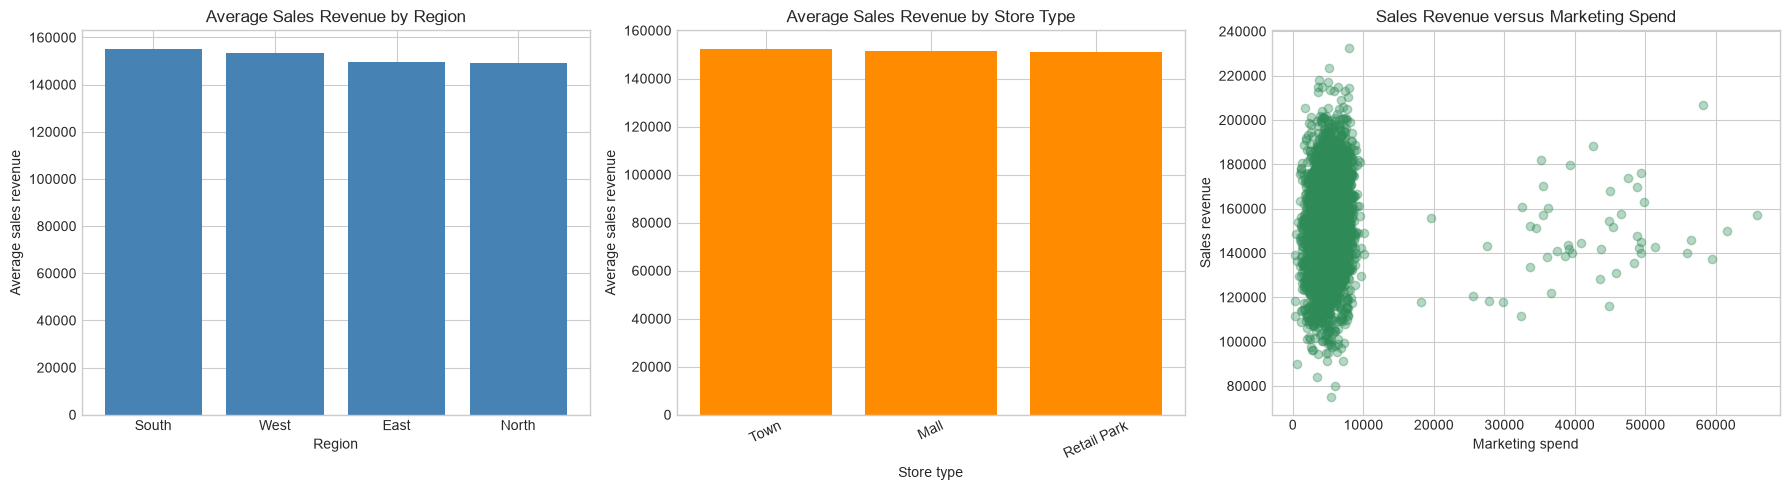

In [71]:
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

region_chart = retail_clean.groupby('Region', as_index=False)['SalesRevenue'].mean().sort_values('SalesRevenue', ascending=False)
axes[0].bar(region_chart['Region'], region_chart['SalesRevenue'], color='steelblue')
axes[0].set_title('Average Sales Revenue by Region')
axes[0].set_xlabel('Region')
axes[0].set_ylabel('Average sales revenue')

store_chart = retail_clean.groupby('StoreType', as_index=False)['SalesRevenue'].mean().sort_values('SalesRevenue', ascending=False)
axes[1].bar(store_chart['StoreType'], store_chart['SalesRevenue'], color='darkorange')
axes[1].set_title('Average Sales Revenue by Store Type')
axes[1].set_xlabel('Store type')
axes[1].set_ylabel('Average sales revenue')
axes[1].tick_params(axis='x', rotation=25)

axes[2].scatter(retail_clean['MarketingSpend'], retail_clean['SalesRevenue'], alpha=0.35, color='seagreen')
axes[2].set_title('Sales Revenue versus Marketing Spend')
axes[2].set_xlabel('Marketing spend')
axes[2].set_ylabel('Sales revenue')

plt.tight_layout()
plt.show()


The first chart compares average revenue between regions. The second compares average revenue between store types. The scatter plot shows whether higher marketing spend tends to occur alongside higher sales revenue; this is an association, not proof of causation.

## Task 1 predictive modelling

The target variable is SalesRevenue. Linear Regression provides a simple baseline, while Random Forest can model non-linear relationships. The same train-test split is used for both models so their results can be compared fairly. Features calculated directly from SalesRevenue are excluded from modelling to avoid target leakage.

In [72]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import numpy as np

target = 'SalesRevenue'
features = [
    'Region', 'StoreType', 'MarketingSpend', 'Footfall', 'OnlineTraffic',
    'StaffHours', 'DiscountRate', 'CustomerSatisfaction',
    'InventoryAvailability', 'CompetitorDistance', 'PreviousMonthSales',
    'Season', 'StaffHoursPerVisitor',
]
X = retail_clean[features]
y = retail_clean[target]

categorical_features = ['Region', 'StoreType', 'Season']
numeric_features = [column for column in features if column not in categorical_features]
preprocessor = ColumnTransformer([
    ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('numeric', 'passthrough', numeric_features),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1),
}

model_results = []
fitted_models = {}
for model_name, estimator in models.items():
    pipeline = Pipeline([('preprocessor', preprocessor), ('model', estimator)])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    model_results.append({
        'Model': model_name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2': r2_score(y_test, predictions),
    })
    fitted_models[model_name] = pipeline

model_results = pd.DataFrame(model_results).sort_values('RMSE')
display(model_results)


,Model,MAE,RMSE,R2
0,Linear Regression,"9,731.96","12,270.22",0.60
1,Random Forest,"10,090.88","12,691.38",0.57


MAE and RMSE measure prediction error, so lower values are better. R? measures the proportion of variation explained by the model, so higher values are better. The model with the lowest RMSE will be selected as the preferred predictive model, while recognising that this is an evaluation on one held-out test sample.

In [73]:
best_model_name = model_results.iloc[0]['Model']
best_model = fitted_models[best_model_name]
print('Preferred model based on lowest RMSE:', best_model_name)

feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()
model_estimator = best_model.named_steps['model']
if hasattr(model_estimator, 'feature_importances_'):
    importance_values = model_estimator.feature_importances_
else:
    importance_values = np.abs(model_estimator.coef_)

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance_values,
}).sort_values('Importance', ascending=False)
display(feature_importance.head(15))


Preferred model based on lowest RMSE: Linear Regression


,Feature,Importance
2,categorical__Region_South,"3,695.68"
1,categorical__Region_North,"3,123.93"
20,numeric__StaffHoursPerVisitor,"2,903.29"
0,categorical__Region_East,"1,834.59"
3,categorical__Region_West,"1,262.83"
17,numeric__InventoryAvailability,779.30
10,categorical__Season_Winter,472.08
9,categorical__Season_Summer,334.57
6,categorical__StoreType_Town,156.47
14,numeric__StaffHours,145.25


## Outlier investigation

The IQR rule flags values below Q1 - 1.5 times IQR or above Q3 + 1.5 times IQR. These are potential outliers for investigation, not automatic errors, so they are retained in the cleaned dataset.

In [74]:
numeric_columns = retail_clean.select_dtypes(include='number').columns
outlier_rows = []
for column in numeric_columns:
    q1 = retail_clean[column].quantile(0.25)
    q3 = retail_clean[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    count = int(((retail_clean[column] < lower_bound) | (retail_clean[column] > upper_bound)).sum())
    outlier_rows.append({
        'Feature': column,
        'Lower bound': lower_bound,
        'Upper bound': upper_bound,
        'Potential outliers': count,
    })

iqr_outlier_summary = pd.DataFrame(outlier_rows).sort_values('Potential outliers', ascending=False)
display(iqr_outlier_summary)


,Feature,Lower bound,Upper bound,Potential outliers
13,MarketingROI,6.78,55.54,355
12,RevenuePerVisitor,37.77,222.21,283
14,StaffHoursPerVisitor,-0.00,0.60,235
11,SalesGrowthRate,0.20,4.69,153
1,MarketingSpend,"1,394.13","8,656.68",123
3,OnlineTraffic,"2,421.61","14,533.20",69
6,CustomerSatisfaction,50.62,99.96,61
9,PreviousMonthSales,"20,646.77","68,981.28",47
2,Footfall,279.32,"2,129.11",43
4,StaffHours,131.01,566.72,33


Potential outliers were retained because an extreme value may represent a genuine high-performing or low-performing store. The summary should be reviewed alongside the business context before any values are removed or transformed.